(35064, 26)


,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,...,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
count,35045.000000,35046.000000,35046.0,35046.000000,35046.000000,35045.000000,35046.0,35046.0,35046.0,35045.000000,...,35046.000000,35045.000000,35046.0,35046.000000,35064.000000,35064.000000,35064.000000,35028.000000,35064.000000,35064.000000
mean,383.513540,448.059208,0.0,5622.737488,4256.065742,298.319789,0.0,0.0,0.0,475.577343,...,1432.665925,269.452133,0.0,5464.479769,1439.066735,5471.216689,28712.129962,28696.939905,49.874341,57.884023
std,85.353943,354.568590,0.0,2201.830478,1961.601013,52.520673,0.0,0.0,0.0,792.406614,...,1680.119887,50.195536,0.0,3213.691587,1677.703355,3176.312853,4594.100854,4574.987950,14.618900,14.204083
min,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,237.000000,18105.000000,18041.000000,2.060000,9.330000
25%,333.000000,0.000000,0.0,4126.000000,2527.000000,263.000000,0.0,0.0,0.0,0.000000,...,71.000000,240.000000,0.0,2933.000000,69.000000,2979.000000,24793.750000,24807.750000,41.490000,49.347500
50%,367.000000,509.000000,0.0,4969.000000,4474.000000,300.000000,0.0,0.0,0.0,68.000000,...,616.000000,279.000000,0.0,4849.000000,576.000000,4855.000000,28906.000000,28901.000000,50.520000,58.020000
75%,433.000000,757.000000,0.0,6429.000000,5838.750000,330.000000,0.0,0.0,0.0,616.000000,...,2578.000000,310.000000,0.0,7398.000000,2636.000000,7353.000000,32263.250000,32192.000000,60.530000,68.010000
max,592.000000,999.000000,0.0,20034.000000,8359.000000,449.000000,0.0,0.0,0.0,4523.000000,...,5792.000000,357.000000,0.0,17436.000000,5836.000000,17430.000000,41390.000000,41015.000000,101.990000,116.800000


repeated columns are Index(['generation fossil oil shale', 'generation fossil peat',
       'generation geothermal', 'generation wind offshore'],
      dtype='object')
time deltas are all the same
time delta is 1hour
1     29
21    12
20     6
Name: count, dtype: int64
36


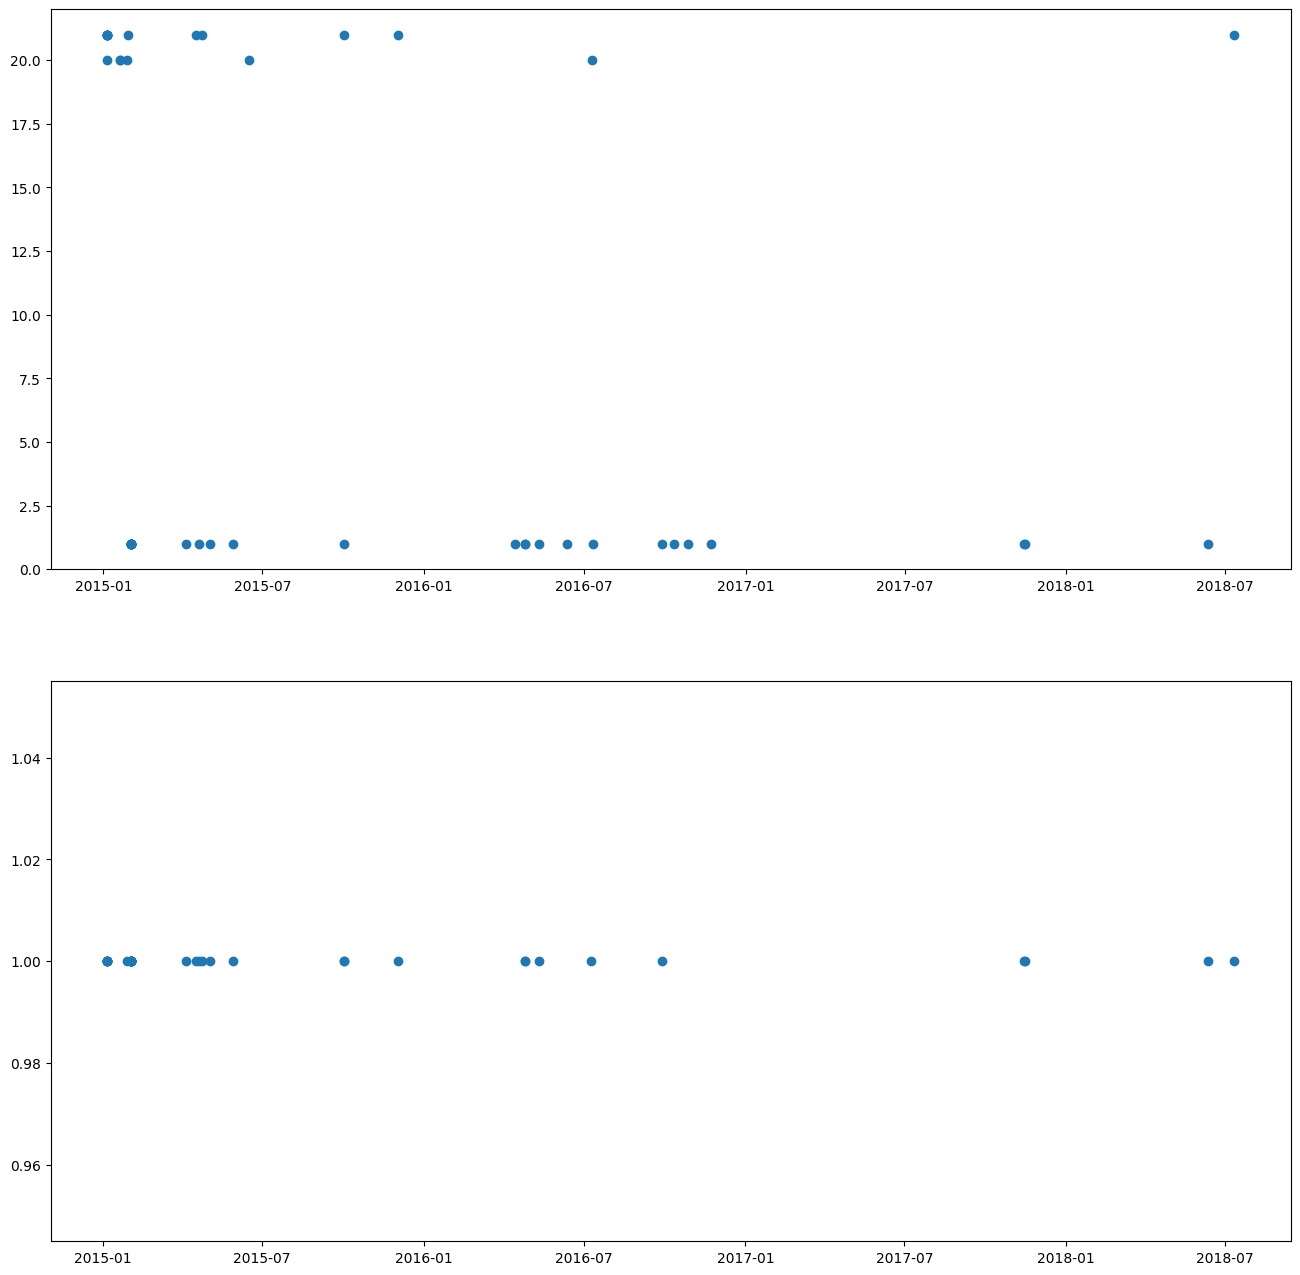

DatetimeIndex(['2015-01-05 11:00:00+00:00', '2015-01-05 12:00:00+00:00',
               '2015-01-05 13:00:00+00:00', '2015-01-05 14:00:00+00:00',
               '2015-01-05 15:00:00+00:00', '2015-01-05 16:00:00+00:00',
               '2015-01-28 12:00:00+00:00', '2015-02-01 06:00:00+00:00',
               '2015-02-01 07:00:00+00:00', '2015-02-01 08:00:00+00:00',
               '2015-02-01 11:00:00+00:00', '2015-02-01 12:00:00+00:00',
               '2015-02-01 13:00:00+00:00', '2015-02-01 14:00:00+00:00',
               '2015-02-01 15:00:00+00:00', '2015-02-01 16:00:00+00:00',
               '2015-02-01 17:00:00+00:00', '2015-02-01 18:00:00+00:00',
               '2015-04-05 01:00:00+00:00', '2015-04-16 07:00:00+00:00',
               '2015-04-20 06:00:00+00:00', '2015-04-23 19:00:00+00:00',
               '2015-05-02 08:00:00+00:00', '2015-05-29 01:00:00+00:00',
               '2015-10-02 06:00:00+00:00', '2015-10-02 09:00:00+00:00',
               '2015-12-02 08:00:00+00:00', '2016-0

In [77]:
import pandas as pd
df = pd.read_csv('energy_dataset.csv')


df["time"] = pd.to_datetime(df["time"],utc=True)
df = df.sort_values("time",ascending=True).set_index("time")

null_count = df.isnull().sum()/df.shape[0]
df = df.dropna(how="all",axis=1)

print(df.shape)
display(df.describe())

df.index.duplicated().any()
repeat = df.T.duplicated()
mod_df = df.loc[:,~repeat]
repeated_columns = df.columns[repeat]
print(f"repeated columns are {repeated_columns}")

times = df.index.to_series().diff().dropna()
if len(times.unique())==1:
    print("time deltas are all the same")
    if times.eq(pd.Timedelta("1 hour")).all():
        print("time delta is 1hour")
else:
    print(times.unique())

bar_na = df.isnull().sum(axis=1)
# bar_na.value_counts().index
print(bar_na.value_counts()[bar_na.value_counts().index>0])
total_load_actual_missing = df["total load actual"].isnull()
print(total_load_actual_missing.sum())

import matplotlib.pyplot as plt

fig,ax = plt.subplots(2,1,figsize=(16,16))
total_load_actual_missing_df = total_load_actual_missing[total_load_actual_missing]
missing_df = bar_na[bar_na>0]
ax[1].scatter(total_load_actual_missing_df.index,total_load_actual_missing_df)
ax[0].scatter(missing_df.index,missing_df)
plt.show()

print(total_load_actual_missing_df.index)
print("common large missing point is ",missing_df[missing_df>1].index.intersection(total_load_actual_missing_df.index))

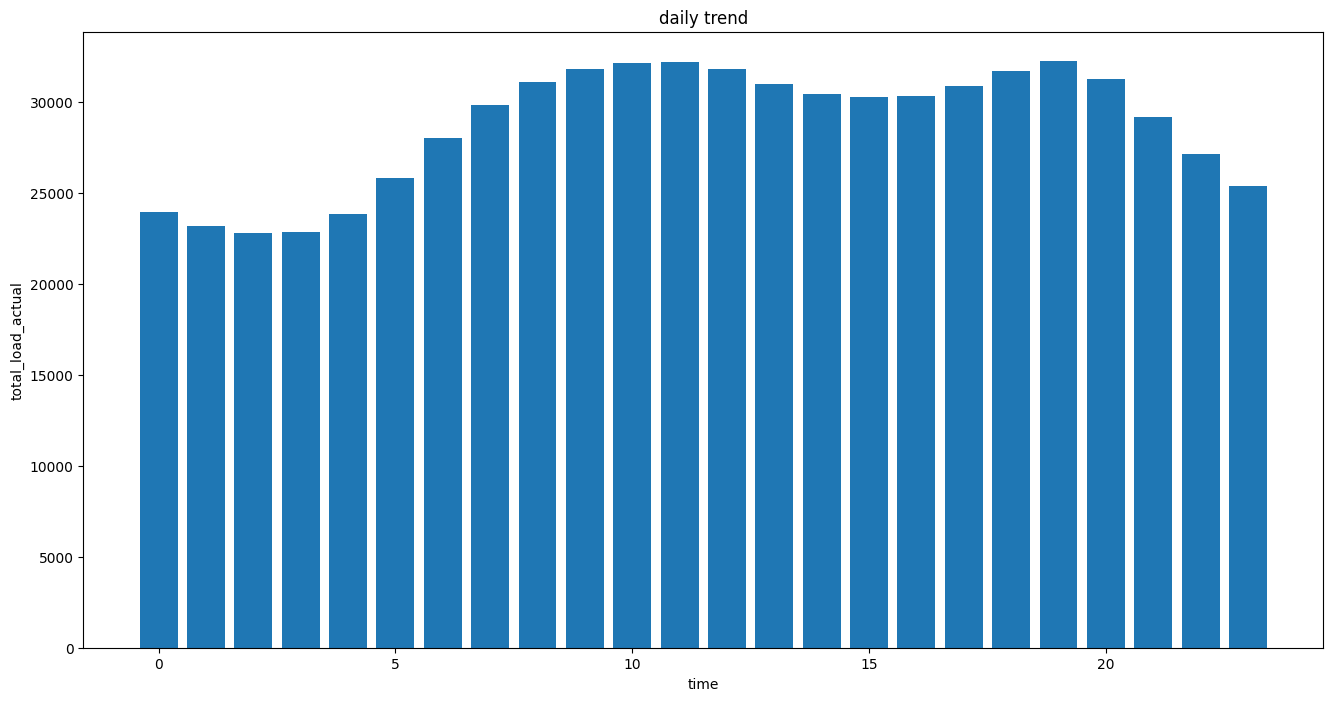

In [99]:
daily_load = df.groupby(df.index.hour)["total load actual"].mean()
fig,ax = plt.subplots(figsize=(16,8))
ax.bar(daily_load.index,daily_load)
ax.set_title("daily trend")
ax.set_xlabel("time")
ax.set_ylabel("total_load_actual")
plt.show()

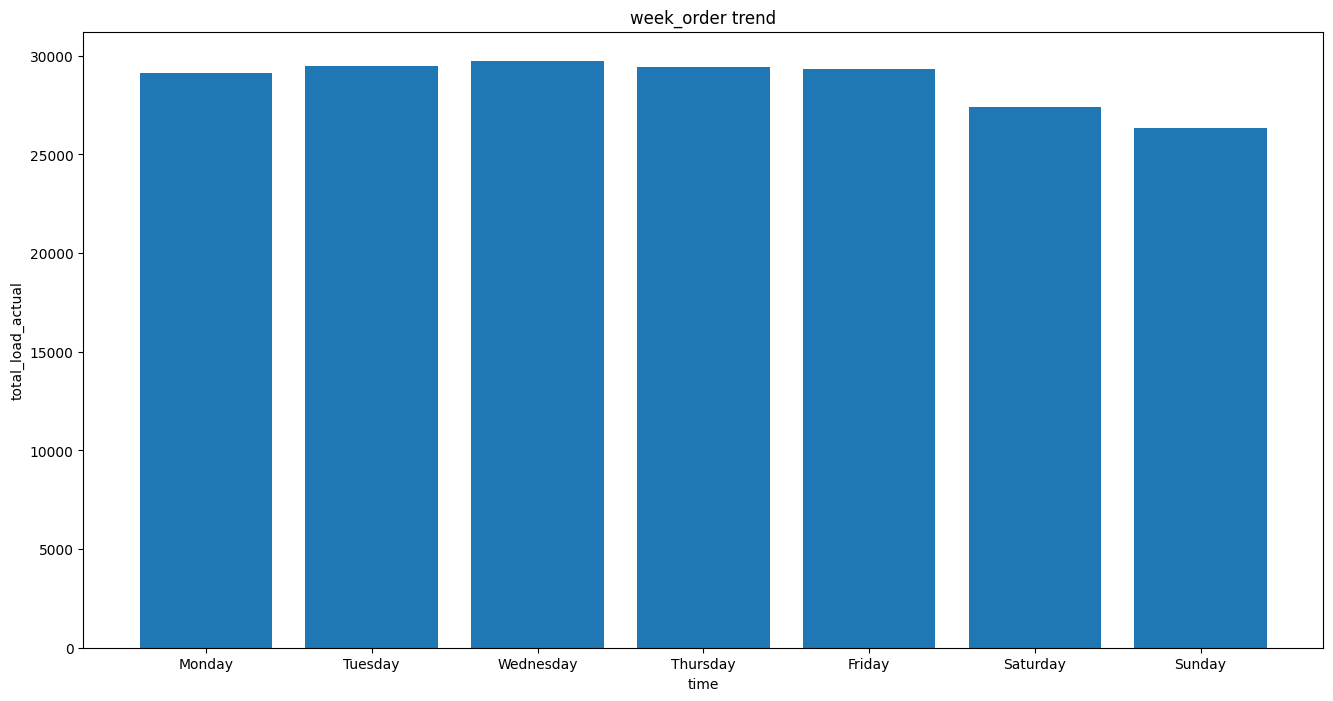

In [106]:
week_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
week_load = df.groupby(df.index.day_name())["total load actual"].mean().reindex(week_order)
fig,ax = plt.subplots(figsize=(16,8))
ax.bar(week_load.index,week_load)
ax.set_title("week_order trend")
ax.set_xlabel("time")
ax.set_ylabel("total_load_actual")
plt.show()

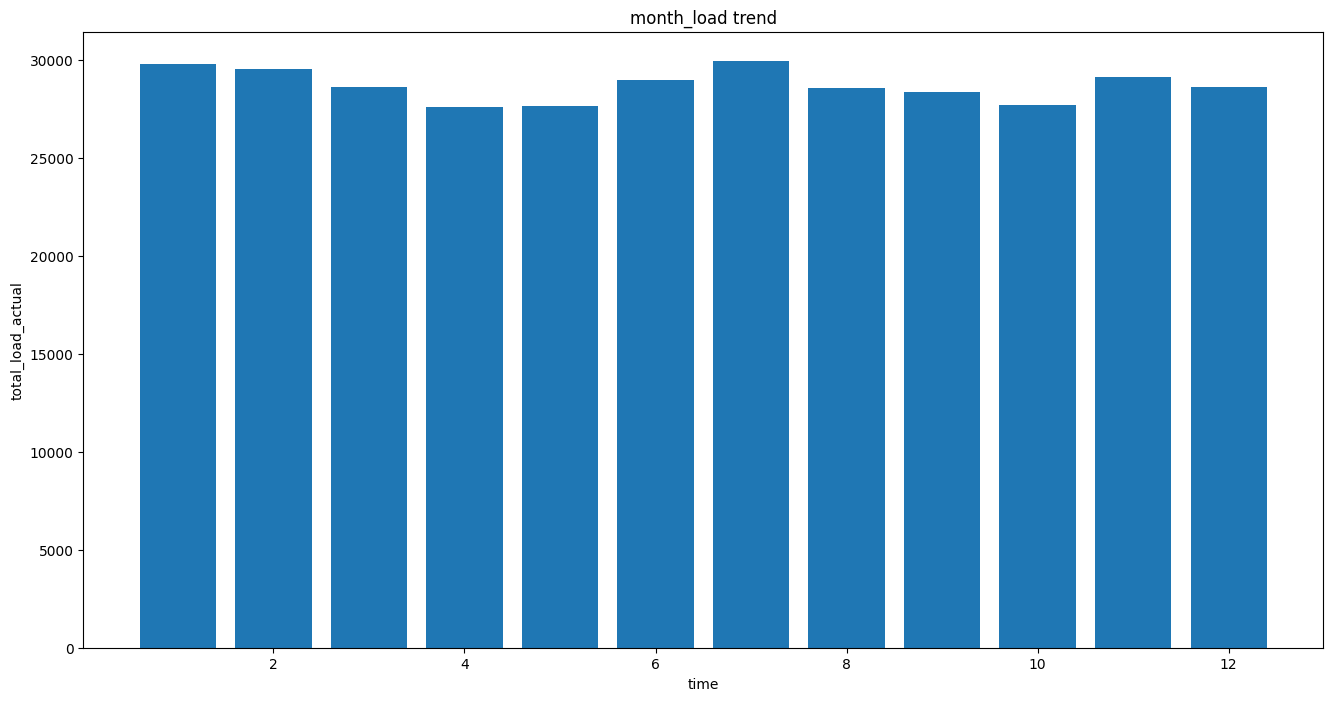

In [105]:
month_load = df.groupby(df.index.month)["total load actual"].mean()
fig,ax = plt.subplots(figsize=(16,8))
ax.bar(month_load.index,month_load)
ax.set_title("month_load trend")
ax.set_xlabel("time")
ax.set_ylabel("total_load_actual")
plt.show()

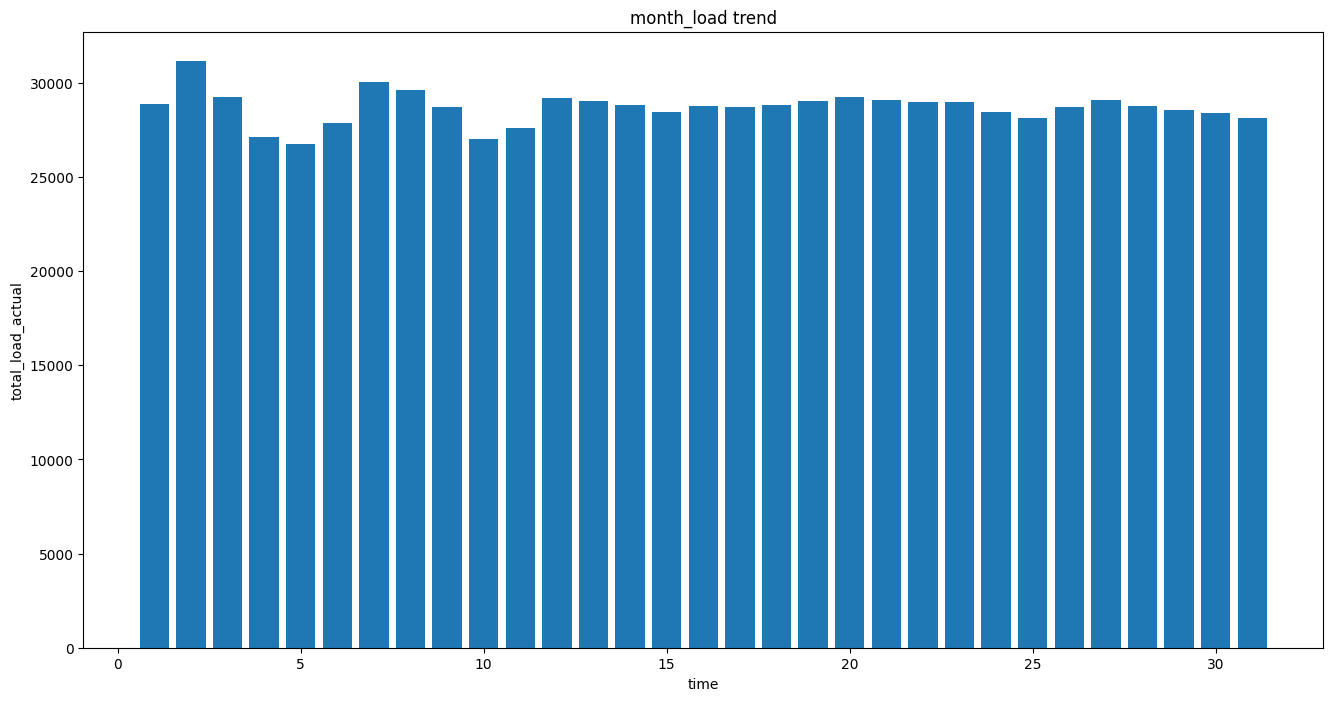

In [104]:
daily_load = df.groupby(df.index.day)["total load actual"].mean()
fig,ax = plt.subplots(figsize=(16,8))
ax.bar(daily_load.index,daily_load)
ax.set_title("month_load trend")
ax.set_xlabel("time")
ax.set_ylabel("total_load_actual")
plt.show()

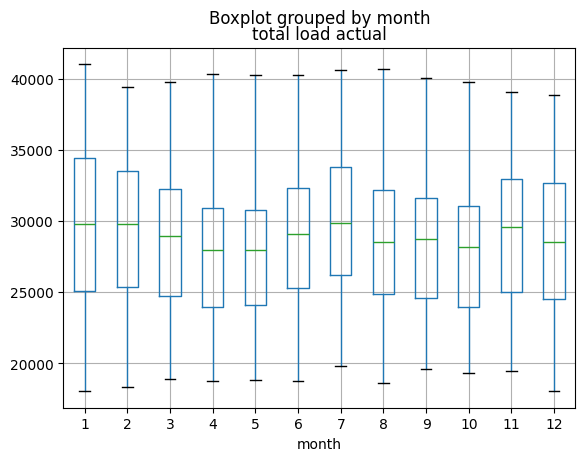

In [108]:
plot_df = df.copy()
plot_df['month'] = plot_df.index.month
ax = plot_df.boxplot(column="total load actual",by="month")
